# Question Answering (QA) — Classroom Notebook

This notebook follows this flow:

1. Load packages.
2. Download a **small** QA dataset (SQuAD v1) and create small subsets for speed.
3. Take a tiny portion of the validation set and show predictions **before training**.
4. Train a small model for **1 epoch** on a tiny subset.
5. Show **after-training** predictions on the same tiny validation slice.
6. Evaluate the model on (a) validation and (b) a pseudo-test split derived from validation.

> Note: SQuAD v1 does not provide official test answers. We split validation into two parts and call the second part "test" for teaching only.

## 0) Setup
This cell:
- Installs/loads minimal packages (`transformers`, `datasets`, `evaluate`, `accelerate`).
- Sets a deterministic random seed.

In [ ]:
# %% DOCSTRING
# We explicitly disable Weights & Biases (wandb) logging by setting WANDB_DISABLED.
# We also request that the Hugging Face Trainer does not report to any external service.

import os


# Install minimal packages quietly (first run may take a minute to download wheels/models):
!pip -q install transformers datasets evaluate accelerate > /dev/null

import random, numpy as np, torch
from typing import List, Dict
from datasets import load_dataset
import evaluate
from transformers import (
    AutoTokenizer,
    AutoModelForQuestionAnswering,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    pipeline,
)

seed = 42
random.seed(seed); np.random.seed(seed)
if torch.cuda.is_available():
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
print("CUDA available:", torch.cuda.is_available())

## 1) Load a Small Dataset Slice (SQuAD v1)
We use **SQuAD v1** (train + validation). For speed:
- Train on a tiny subset (e.g., 10,000 examples).
- Evaluate on validation; also create a pseudo-**test** split by halving the validation set.
- Dataset URL : https://huggingface.co/datasets/rajpurkar/squad
- Total rows in dataset : 87.6k

In [ ]:
raw = load_dataset("rajpurkar/squad") ##load dataset from huggingface


#raw contains the train:validation:test split of the data

train = raw["train"].shuffle(seed=seed)
val_full = raw["validation"].shuffle(seed=seed)

# optional: keep a small train subset for faster training
train = train.select(range(10000))

# tiny preview set
val_small = val_full.select(range(10))

# split validation into val / pseudo-test
mid = len(val_full) // 2
val = val_full.select(range(mid))
test = val_full.select(range(mid, len(val_full)))

len(train), len(val_small), len(val), len(test)

## 2) Define Model & Tokenizer
We start from a **base language model** (`distilbert-base-uncased`) **not** fine-tuned on QA. Its initial predictions will be poor—this is expected and useful for demonstration.

In [ ]:
# %% DOCSTRING
# Load a base model+tokenizer that has NOT been QA-fine-tuned yet.
# We'll fine-tune it on our tiny SQuAD slice.

base_model = "distilbert-base-uncased" #name of the pre-trained model
tokenizer = AutoTokenizer.from_pretrained(base_model, use_fast=True) #loads tokenizer associated with the base model
model = AutoModelForQuestionAnswering.from_pretrained(base_model) #load with a question answering head

print("Loaded base model:", base_model)

# Question : Can pre-trained BERT family of models generate text?

```mermaid
flowchart TD

    A["Question + Context"]

    subgraph B["DistilBERT Encoder"]
        direction TB
        B1["Embeddings"]
        B2["Transformer Layer 1"]
        B3["Transformer Layer 2"]
        B4["⋮"]
        B5["Transformer Layer 6"]

        B1 --> B2
        B2 --> B3
        B3 --> B4
        B4 --> B5
    end

    C["Token Hidden States<br/>h₁, h₂, h₃, ..., hₙ"]

    D["Question Answering Head<br/>Linear Layer: len(hₙ) → 2"]

    E["Start Logits"]
    F["End Logits"]

    G["Start Probability<br/>for Every Token"]
    H["End Probability<br/>for Every Token"]

    I["Predicted Answer Span"]

    A --> B1
    B5 --> C
    C --> D

    D --> E
    D --> F

    E --> G
    F --> H

    G --> I
    H --> I
```
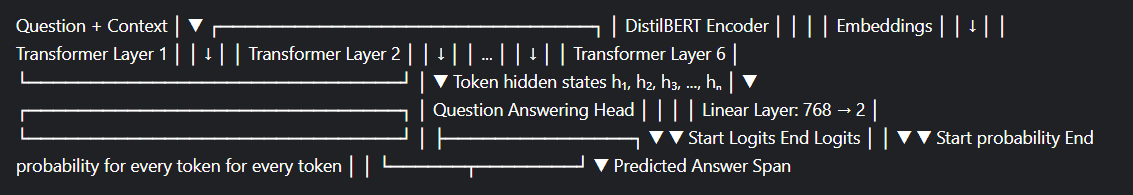
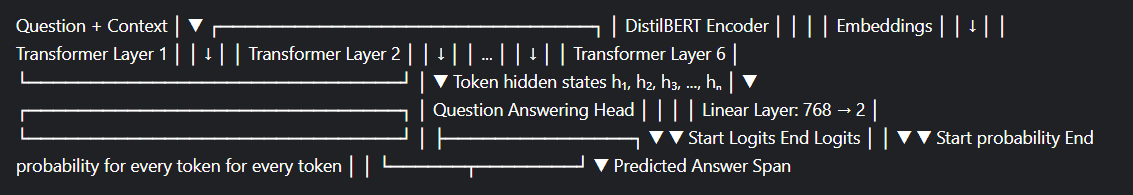

### Logit to probability :

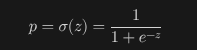

Given:
$$
p = \sigma(z) = \frac{1}{1 + e^{-z}}
$$
Solve for $z$:
$$
p(1 + e^{-z}) = 1
$$
$$
pe^{-z} = 1-p
$$
$$
e^{-z} = \frac{1-p}{p}
$$
Taking $\ln$:
$$
-z = \ln\left(\frac{1-p}{p}\right)
$$
Therefore:
$$
\boxed{z = \ln\left(\frac{p}{1-p}\right)}
$$
This is the **logit function**:
$$
\boxed{z = \operatorname{logit}(p)}
$$

Range of p is [0,1] whereas range of z is (-infinity, infinity).

## 3) Pre-Training Predictions (Tiny Validation Slice)
We run a QA pipeline **before** any fine-tuning to show baseline behavior.

Exercise 1:

In [ ]:
import torch

### select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device) ### move model to GPU
model.eval() ### switches the model to inference mode


def qa_predict(question, context):

    inputs = tokenizer(
        question,
        context,
        return_tensors="pt", ### tells huggingface tokenizer to return as tensor datatype
        truncation="only_second", ### if context is too long, only context is truncated
        max_length=384
    )
 ### move every tensor to GPU
    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():  ### no training
        outputs = model(**inputs)

    start_idx = torch.argmax(
        outputs.start_logits,
        dim=-1
    ).item()  ### convert tensor to int

    end_idx = torch.argmax(
        outputs.end_logits,
        dim=-1
    ).item()

    if end_idx < start_idx:  ### explain
        end_idx = start_idx

    answer_tokens = inputs["input_ids"][0][
        start_idx:end_idx + 1
    ]

    answer = tokenizer.decode(
        answer_tokens,
        skip_special_tokens=True
    )

    # Exercise 1 : Write the following code to calculate probability from logits
    start_probs = torch._______(  #write which function to use
        ___________________,      #write which logit to use
        dim=-1
    )

    end_probs = torch._________(  #write which function to use
        ___________________,      #write which logit to use
        dim=-1
    )
#________________________________________________________________________
    score = (
        start_probs[0, start_idx]
        * end_probs[0, end_idx]
    ).item()

    return {
        "answer": answer,
        "score": score
    }

Steps (Recap - Pre-requisite for Exercise 2) : 
- Select device.
- Move model to selected device.
- Use model in inference mode.
- Define inputs (tokenize tokens from context and question).
- Record outputs for every token by freezing the model weights.
- Find start and end index.
- Find the span from the context, that contains the answer.

Solution: 

In [ ]:
import torch

### select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device) ### move model to GPU
model.eval() ### switches the model to inference mode


def qa_predict(question, context):

    inputs = tokenizer(
        question,
        context,
        return_tensors="pt",
        truncation="only_second", ###### if context is too long, only context is truncated
        max_length=384
    )
 ### move every tensor to GPU
    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():  ### no training
        outputs = model(**inputs)

    start_idx = torch.argmax(
        outputs.start_logits,
        dim=-1
    ).item()  ### convert tensor to int

    end_idx = torch.argmax(
        outputs.end_logits,
        dim=-1
    ).item()

    if end_idx < start_idx:  ### explain
        end_idx = start_idx

    answer_tokens = inputs["input_ids"][0][
        start_idx:end_idx + 1
    ]

    answer = tokenizer.decode(
        answer_tokens,
        skip_special_tokens=True
    )

    # Confidence
    start_probs = torch.softmax(
        outputs.start_logits,
        dim=-1
    )

    end_probs = torch.softmax(
        outputs.end_logits,
        dim=-1
    )

    score = (
        start_probs[0, start_idx]
        * end_probs[0, end_idx]
    ).item()

    return {
        "answer": answer,
        "score": score
    }

In [ ]:
def preview_predictions(ds, n=5):

    for i in range(min(n, len(ds))):

        q = ds[i]["question"]
        ctx = ds[i]["context"]
        ans = ds[i]["answers"]["text"][0]

        out = qa_predict(
            question=q,
            context=ctx
        )

        print(
            f"[{i}] Q: {q}\n"
            f"    GOLD: {ans}\n"
            f"    PRED: {out['answer']} "
            f"(score={out['score']:.3e})\n"
        )


print("Predictions BEFORE training:\n")

preview_predictions(
    val_small,
    n=len(val_small)
)

## 4) Prepare Features & Train (1 epoch)
We tokenize question+context with sliding windows so answers align with token spans. We keep the training very short for class speed.

# What do we need to train the model on?

```mermaid
flowchart TD
    A["SQuAD example<br/>question + long context<br/>answer as character span"] --> B["Tokenizer<br/>max_length=384, doc_stride=128"]

    B --> C1["Window 1<br/>[CLS] Q [SEP] context chunk 1 [SEP]"]
    B --> C2["Window 2<br/>[CLS] Q [SEP] context chunk 2 [SEP]"]
    B --> C3["Window 3<br/>[CLS] Q [SEP] context chunk 3 [SEP]"]

    C1 --> D1{"Answer fully<br/>inside this window?"}
    C2 --> D2{"Answer fully<br/>inside this window?"}
    C3 --> D3{"Answer fully<br/>inside this window?"}

    D1 -->|Yes| E1["Labels: start_tok, end_tok<br/>answer token span"]
    D1 -->|No| F1["Labels: [CLS], [CLS]<br/>no answer in window"]

    D2 -->|Yes| E2["Labels: start_tok, end_tok"]
    D2 -->|No| F2["Labels: [CLS], [CLS]"]

    D3 -->|Yes| E3["Labels: start_tok, end_tok"]
    D3 -->|No| F3["Labels: [CLS], [CLS]"]

    E1 --> G["Training features<br/>input_ids + start/end positions"]
    F1 --> G
    E2 --> G
    F2 --> G
    E3 --> G
    F3 --> G

In [ ]:
# %% DOCSTRING
# Tokenization function for extractive QA (maps answer char positions to token start/end).
# We use a common setup: max_length=384 and doc_stride=128.

max_length = 384
doc_stride = 128

def prepare_train_features(examples):
    tokenized = tokenizer(
        examples["question"],
        examples["context"],
        truncation="only_second",
        max_length=max_length,
        stride=doc_stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding="max_length",
    )
    sample_mapping = tokenized.pop("overflow_to_sample_mapping")
    offset_mapping = tokenized.pop("offset_mapping")
    start_positions, end_positions = [], []

    for i, offsets in enumerate(offset_mapping):
        input_ids = tokenized["input_ids"][i]
        cls_index = input_ids.index(tokenizer.cls_token_id)
        sample_idx = sample_mapping[i]
        answers = examples["answers"][sample_idx]

        if len(answers["answer_start"]) == 0:
            start_positions.append(cls_index)
            end_positions.append(cls_index)
        else:
            start_char = answers["answer_start"][0]
            end_char = start_char + len(answers["text"][0])
            sequence_ids = tokenized.sequence_ids(i)
            # Find the context token span
            idx = 0
            while idx < len(sequence_ids) and sequence_ids[idx] != 1:
                idx += 1
            context_start = idx
            while idx < len(sequence_ids) and sequence_ids[idx] == 1:
                idx += 1
            context_end = idx - 1

            # If answer not fully inside the context window, label [CLS]
            if not (offsets[context_start][0] <= start_char and offsets[context_end][1] >= end_char):
                start_positions.append(cls_index)
                end_positions.append(cls_index)
            else:
                # Move start to the right token
                start_idx = context_start
                while start_idx <= context_end and offsets[start_idx][0] <= start_char:
                    start_idx += 1
                start_positions.append(start_idx - 1)
                # Move end to the left token
                end_idx = context_end
                while end_idx >= context_start and offsets[end_idx][1] >= end_char:
                    end_idx -= 1
                end_positions.append(end_idx + 1)

    tokenized["start_positions"], tokenized["end_positions"] = start_positions, end_positions
    return tokenized

train_tok = train.map(prepare_train_features, batched=True, remove_columns=train.column_names)

data_collator = DataCollatorWithPadding(tokenizer)

# Keep TrainingArguments minimal and version-friendly — no 'evaluation_strategy'.
args = TrainingArguments(
    output_dir="qa-ft-output",
    learning_rate=3e-5, #####
    per_device_train_batch_size=8, #####
    num_train_epochs=1,  #####
    weight_decay=0.01,   ### uses regularization to shrink weights
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    save_strategy="no", ### save checkpoints after every epoch?
    report_to=[]  # do not report to wandb or any external service
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    processing_class=tokenizer,
    data_collator=data_collator,
)
train_out = trainer.train()
train_out.metrics

In [ ]:
# %% DOCSTRING
# Save the fine-tuned QA model and tokenizer.

save_path = "fine_tuned_squad_qa"

# Save fine-tuned model
trainer.model.save_pretrained(save_path)

# Save tokenizer
tokenizer.save_pretrained(save_path)

print(f"Fine-tuned model saved to: {save_path}")

## SAVE LOCALLY

In [ ]:
import shutil

folder_path = "/kaggle/working/fine_tuned_squad_qa"
zip_path = "/kaggle/working/fine_tuned_squad_qa"

shutil.make_archive(
    zip_path,
    "zip",
    folder_path
)

print("Created:", zip_path + ".zip")

In [ ]:
!zip -r /kaggle/working/fine_tuned_squad_qa.zip /kaggle/working/fine_tuned_squad_qa

## 5) Post-Training Predictions (Same Tiny Slice)
We rebuild the QA pipeline using the **fine-tuned** model now and run predictions again on the same small examples.

Exercise 2 : Write the pseudo-code/logic for evaluation.

Hint : Similar to inference before training


In [ ]:
# %% DOCSTRING
# Use the fine-tuned model directly and preview predictions AFTER training.

import torch

# Get the fine-tuned model from Trainer
model = trainer.model

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)
model.eval()


def qa_predict(question, context, max_answer_length=30):

    inputs = tokenizer(
        question,
        context,
        return_tensors="pt",
        truncation="only_second",
        max_length=384,
        return_offsets_mapping=True
    )

    # Save offset mapping
    offset_mapping = inputs.pop("offset_mapping")[0]

    # Identify question/context tokens
    sequence_ids = inputs.sequence_ids(0)

    # Move model inputs to device
    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)

    start_logits = outputs.start_logits[0]
    end_logits = outputs.end_logits[0]

    # Only allow answer tokens from the context
    context_indices = [
        i
        for i, seq_id in enumerate(sequence_ids)
        if seq_id == 1
    ]

    best_score = float("-inf")
    best_start = None
    best_end = None

    # Find best valid answer span
    for start_idx in context_indices:

        max_end = min(
            start_idx + max_answer_length,
            context_indices[-1] + 1
        )

        for end_idx in range(start_idx, max_end):

            if sequence_ids[end_idx] != 1:
                continue

            score = (
                start_logits[start_idx]
                + end_logits[end_idx]
            ).item()

            if score > best_score:
                best_score = score
                best_start = start_idx
                best_end = end_idx

    # Convert token positions back to character positions
    start_char = offset_mapping[best_start][0].item()
    end_char = offset_mapping[best_end][1].item()

    answer = context[start_char:end_char]

    # Confidence score
    start_probs = torch.softmax(start_logits, dim=0)
    end_probs = torch.softmax(end_logits, dim=0)

    confidence = (
        start_probs[best_start]
        * end_probs[best_end]
    ).item()

    return {
        "answer": answer,
        "score": confidence
    }


def preview_predictions(ds, n=4):

    for i in range(min(n, len(ds))):

        q = ds[i]["question"]
        ctx = ds[i]["context"]
        gold = ds[i]["answers"]["text"][0]

        out = qa_predict(
            question=q,
            context=ctx
        )

        print("=" * 100)
        print(f"SAMPLE {i + 1}")
        print("=" * 100)

        print("\nCONTEXT:")
        print(ctx)

        print("\nQUESTION:")
        print(q)

        print("\nGOLD ANSWER:")
        print(gold)

        print("\nPREDICTED ANSWER:")
        print(out["answer"])

        print("\nCONFIDENCE SCORE:")
        print(f"{out['score']:.6f}")

        print("\n")


print("Predictions AFTER training:\n")

preview_predictions(
    val_small,
    n=4
)

## 6) Evaluation (EM/F1 on Validation + Pseudo-Test)
We compute **Exact Match (EM)** and **F1** using the official SQuAD metric package.

- `val_half` = first half of validation (acts as real **validation**).
- `test_half` = second half of validation (acts as a **test** proxy).

In [ ]:
# %% DOCSTRING
# Utility to tokenize validation features and to extract predictions as text answers
squad_metric = evaluate.load("squad")

def prepare_validation_features(examples):
    tokenized = tokenizer(
        examples["question"],
        examples["context"],
        truncation="only_second",
        max_length=max_length,
        stride=doc_stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding="max_length",
    )
    sample_mapping = tokenized.pop("overflow_to_sample_mapping")
    tokenized["example_id"] = []
    for i in range(len(tokenized["input_ids"])):
        sample_index = sample_mapping[i]
        tokenized["example_id"].append(examples["id"][sample_index])
    return tokenized

def predict_and_score(dataset):
    features = dataset.map(prepare_validation_features, batched=True, remove_columns=dataset.column_names)
    preds = trainer.predict(features)
    start_logits, end_logits = preds.predictions
    # Simple best-span decoding per feature; pick max start+end logit span
    final_predictions = []
    for ex in dataset:
        ex_id = ex["id"]
        # all features for this example:
        idxs = [i for i, fid in enumerate(features["example_id"]) if fid == ex_id]
        best_text, best_score = "", -1e9
        for i in idxs:
            s_idx = int(np.argmax(start_logits[i]))
            e_idx = int(np.argmax(end_logits[i]))
            if e_idx < s_idx:  # skip invalid spans
                continue
            input_ids = features["input_ids"][i]
            text = tokenizer.decode(input_ids[s_idx:e_idx+1], skip_special_tokens=True)
            score = float(np.max(start_logits[i]) + np.max(end_logits[i]))
            if score > best_score:
                best_text, best_score = text, score
        final_predictions.append({"id": ex_id, "prediction_text": best_text})
    references = [{"id": ex["id"], "answers": ex["answers"]} for ex in dataset]
    return squad_metric.compute(predictions=final_predictions, references=references)

print("Validation metrics:")
val_metrics = predict_and_score(val_half)
print(val_metrics)

print("\nPseudo-Test metrics:")
test_metrics = predict_and_score(test_half)
print(test_metrics)

## 7) Suggestions for Students
Here are easy extensions to try:

1. Try some adversarial examples

```
Engineer David Miller designed the outer casing. The device was invented by Maria Chen during her doctoral research. Robert Lee later patented an improved version, while James Wilson supervised its commercial production.

Who invented the device?
```

```
For many years, textbooks reported 1960 as the year stromules were first observed. Later examination of the original laboratory records showed that this date was incorrect. The observations actually occurred in 1962.

When were stromules first observed?
```

2. **Train longer:** set `num_train_epochs=2 or 3` and/or increase `max_train`.
3. **Bigger model:** switch `base_model` to `bert-base-uncased` or `roberta-base`.
4. **Learning rate sweep:** try `5e-5` or `2e-5` and compare EM/F1.



## ADVERSARIAL TESTING

In [ ]:
# Adversarial QA test

context = """
For many years, textbooks reported 1960 as the year stromules were first observed. Later examination of the original laboratory records showed that this date was incorrect. The observations actually occurred in 1962.
"""

question = "When were stromules first observed?"

gold_answer = "1962"

# Run the fine-tuned QA model
result = qa_predict(
    question=question,
    context=context
)

print("Context:", context)
print("Question:", question)
print("Gold Answer:", gold_answer)
print("Predicted Answer:", result["answer"])
print(f"Score: {result['score']:.6f}")

# Check exact correctness
if result["answer"].strip().lower() == gold_answer.lower():
    print("Result: CORRECT")
else:
    print("Result: INCORRECT")